In [ ]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
train_dir =r'/content/drive/MyDrive/ms_data/train'
test_dir=r'/content/drive/MyDrive/ms_data/test'


In [ ]:

import tensorflow as tf
from tensorflow.keras import initializers
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import random
seed=14
np.random.seed=seed
img_width=512
img_height=512
img_channels=3

In [ ]:
train_dir =r'/content/drive/MyDrive/ms_data/train'
test_dir=r'/content/drive/MyDrive/ms_data/test'


In [ ]:
train_img_dir = os.path.join(train_dir,'images/')
train_mask_dir = os.path.join(train_dir,'masks/')
test_img_dir = os.path.join(test_dir,'images/')
test_mask_dir = os.path.join(test_dir,'masks/')

In [ ]:
print(train_img_dir)
test_img_count = len(os.listdir(test_img_dir))
train_img_count=len(os.listdir(train_img_dir))
train_img_ids = os.listdir(train_img_dir)
test_img_ids = os.listdir(test_img_dir)
train_mask_count=len(os.listdir(train_mask_dir))
train_mask_ids=os.listdir(train_mask_dir)
print('Train image count is',train_img_count,'and their ids are',train_img_ids)
print('Mask image count is',train_mask_count,'and theur ids are',train_mask_ids)

/content/drive/MyDrive/ms_data/train/images/
Train image count is 1108 and their ids are ['11278720_15.png', '11278735_15.png', '11278750_15.png', '11278780_15.png', '11278765_15.png', '11278810_15.png', '11278795_15.png', '11278855_15.png', '11278825_15.png', '11278885_15.png', '11278900_15.png', '11278870_15.png', '11278945_15.png', '11278930_15.png', '11278915_15.png', '11428690_15.png', '11428675_15.png', '11428660_15.png', '11428720_15.png', '11428705_15.png', '11428750_15.png', '11428765_15.png', '11428735_15.png', '11428780_15.png', '11428795_15.png', '11428825_15.png', '11428810_15.png', '11428930_15.png', '11428840_15.png', '11428855_15.png', '11428945_15.png', '11578660_15.png', '11578690_15.png', '11578675_15.png', '11578705_15.png', '11578720_15.png', '11578735_15.png', '11578765_15.png', '11578750_15.png', '11578780_15.png', '11578795_15.png', '11578810_15.png', '11578840_15.png', '11578825_15.png', '11728660_15.png', '11578855_15.png', '11728690_15.png', '11728705_15.png'

In [ ]:
test_img_count=len(os.listdir(test_img_dir))
test_img_ids=os.listdir(test_img_dir)

In [ ]:
test_img_count = len(os.listdir(test_img_dir))
test_img_ids = os.listdir(test_img_dir)
print('Test image count is',test_img_count,'and their ids are',test_img_ids)

Test image count is 49 and their ids are ['10378780_15.png', '11128870_15.png', '10828720_15.png', '11728825_15.png', '11278840_15.png', '16078870_15.png', '12328750_15.png', '15928855_15.png', '17878885_15.png', '17878735_15.png', '17878780_15.png', '18328735_15.png', '18178780_15.png', '18028750_15.png', '18328780_15.png', '18328960_15.png', '18478735_15.png', '18478930_15.png', '18478900_15.png', '20878930_15.png', '20278885_15.png', '20728960_15.png', '21479035_15.png', '21779005_15.png', '22078975_15.png', '22229050_15.png', '22228900_15.png', '22529065_15.png', '23278915_15.png', '22528885_15.png', '23428540_15.png', '23278930_15.png', '23428810_15.png', '23429080_15.png', '24029035_15.png', '23878540_15.png', '23729020_15.png', '24478825_15.png', '24478855_15.png', '24479215_15.png', '24479170_15.png', '24628885_15.png', '24629200_15.png', '24779275_15.png', '25079170_15.png', '26428735_15.png', '26278720_15.png', '26878690_15.png', '26578720_15.png']


In [ ]:
X_train = np.zeros((train_mask_count,img_width,img_height,img_channels),dtype=np.uint8)
y_train = np.zeros((len(train_mask_ids),img_width,img_height,1),dtype=np.bool_)

In [ ]:
print('Resizing train images and masks')
for n,img_name in tqdm(enumerate(train_mask_ids),total=len(train_mask_ids)):
    path = train_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_train[n] = img
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(train_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_train[n] = mask

Resizing train images and masks


100%|██████████| 1108/1108 [24:47<00:00,  1.34s/it]


In [ ]:
X_test = np.zeros((test_img_count,img_width,img_height,img_channels),dtype=np.uint8)
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)


In [ ]:
print('Resizing test images')
for i,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    path = test_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_test[i] = img

Resizing test images


100%|██████████| 49/49 [01:02<00:00,  1.28s/it]


In [ ]:
print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 49/49 [00:38<00:00,  1.28it/s]


In [ ]:
input_shape = (img_height, img_width, img_channels)

In [ ]:
from tensorflow.keras import models, layers, regularizers
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
#from evaluation_metrics import IoU_coef,IoU_loss

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = conv_block(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = layers.BatchNormalization()(x1)

    x2 = conv_block(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = layers.BatchNormalization()(x2)

    x3 = conv_block(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = layers.BatchNormalization()(x3)

    x4 = conv_block(num_filters, (3, 3), padding="SAME")(x)
    x4 = layers.BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = conv_block(num_filters, (1, 1), padding="SAME")(y)
    return y


In [ ]:
def stem_block(x, n_filter, strides):
    x_init = x

    ## Conv 1
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same")(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)

    ## Add
    x = Add()([x, s])
    return x



In [ ]:
def resnet_block(x, n_filter, strides=1):
    x_init = x

    ## Conv 1
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    ## Conv 2
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=1)(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)

    ## Add
    x = Add()([x, s])
    
    return x

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = Conv2D(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = BatchNormalization()(x1)

    x2 = Conv2D(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = BatchNormalization()(x2)

    x3 = Conv2D(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = BatchNormalization()(x3)

    x4 = Conv2D(num_filters, (3, 3), padding="SAME")(x)
    x4 = BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = Conv2D(num_filters, (1, 1), padding="SAME")(y)
    return y

In [ ]:
def attetion_block(g, x):
    """
        g: Output of Parallel Encoder block
        x: Output of Previous Decoder block
    """

    filters = x.shape[-1]

    g_conv = BatchNormalization()(g)
    g_conv = Activation("relu")(g_conv)
    g_conv = Conv2D(filters, (3, 3), padding="SAME")(g_conv)

    g_pool = MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(g_conv)

    x_conv = BatchNormalization()(x)
    x_conv = Activation("relu")(x_conv)
    x_conv = Conv2D(filters, (3, 3), padding="SAME")(x_conv)

    gc_sum = Add()([g_pool, x_conv])

    gc_conv = BatchNormalization()(gc_sum)
    gc_conv = Activation("relu")(gc_conv)
    gc_conv = Conv2D(filters, (3, 3), padding="SAME")(gc_conv)

    gc_mul = Multiply()([gc_conv, x])
    return gc_mul

In [ ]:
#Attention U-NET
def attentionunet(input_shape, dropout=0.2, batchnorm=True):

    n_filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    upsample_size = 2

    inputs = layers.Input(input_shape)
    c0 = inputs
    c1 = stem_block(c0, n_filters[0], strides=1)

    ## Encoder
    c2 = resnet_block(c1, n_filters[1], strides=2)
    c3 = resnet_block(c2, n_filters[2], strides=2)
    c4 = resnet_block(c3, n_filters[3], strides=2)
    c5 = resnet_block(c4, n_filters[4], strides=2)

    ## Bridge
    b1 = aspp_block(c5, n_filters[4])
    #b2 = aspp_block(c4, n_filters[3])

    ## Decoder
    d0 = attetion_block(c4, b1)
    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block(d0, n_filters[4])

    #d1 = attetion_block(c3, b2)
    d1 = attetion_block(c3, d0)
    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block(d1, n_filters[3])


    d2 = attetion_block(c2, d1)
    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block(d2, n_filters[2])

    d3 = attetion_block(c1, d2)
    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block(d3, n_filters[1])

    ## output
    #outputs = aspp_block(d3, n_filters[0])
    outputs=d3
    outputs = Conv2D(1, (1, 1), padding="same")(outputs)
    outputs = Activation("sigmoid")(outputs)

    ## Model
    model = Model(inputs, outputs)
    model.summary()
    return model


In [ ]:
model = attentionunet(input_shape)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512, 512,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 512, 512,  │         64 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ conv2d_1[0][0],   │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ add[0][0]         │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 16)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 2)   │         32 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 16)  │         32 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 512, 512,  │          0 │ add[0][0],        │
│                     │ 16)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ multiply[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │      4,640 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat

 Total params: 9,196,209 (35.08 MB)

 Trainable params: 9,184,593 (35.04 MB)

 Non-trainable params: 11,616 (45.38 KB)

In [ ]:

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    min_delta=0.0001,
    mode='min',
    restore_best_weights=True,
    verbose=1
)

# Model Checkpoint
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_attention_unet.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# TensorBoard
tensorboard = tf.keras.callbacks.TensorBoard(
    log_dir='logs'
)

# Callback configuration
callbacks = [
    early_stopping,
    model_checkpoint,
    tensorboard
]

# Train the model
results = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=16,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8541 - loss: 0.4029   
Epoch 1: val_loss improved from None to 7068521.50000, saving model to best_attention_unet.keras

Epoch 1: finished saving model to best_attention_unet.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.8674 - loss: 0.3438 - val_accuracy: 0.9032 - val_loss: 7068521.5000
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.8660 - loss: 0.3199
Epoch 2: val_loss did not improve from 7068521.50000
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 242ms/step - accuracy: 0.8712 - loss: 0.3056 - val_accuracy: 0.9032 - val_loss: 259467216.0000
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.8708 - loss: 0.3045
Epoch 3: val_loss improved from 7068521.50000 to 0.27349, saving model to best_attention_unet.keras

Epoch 3: finished saving model to best_attention_unet.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 260ms/step - accuracy: 0.8765 - loss: 0.2958 - val_accuracy: 0.9023 - val_loss: 0.2735
E

{'accuracy': [0.8673940300941467, 0.8711822032928467, 0.8764874935150146, 0.8854199051856995, 0.8997302651405334, 0.9103996157646179, 0.9168346524238586, 0.9203925132751465, 0.9256422519683838, 0.9267169833183289, 0.9284946322441101, 0.9288540482521057, 0.9294406771659851, 0.9322420358657837, 0.9335752129554749, 0.9348835349082947, 0.936294436454773, 0.9364713430404663, 0.9372841715812683, 0.9375215768814087, 0.9378167986869812, 0.9371040463447571, 0.9382030963897705, 0.9397985935211182, 0.94057297706604, 0.9414589405059814, 0.9405141472816467, 0.9415246844291687, 0.9424354434013367, 0.9425655007362366, 0.9430138468742371, 0.9425504803657532, 0.9430246949195862, 0.9441484212875366, 0.9438524842262268, 0.944010317325592, 0.9447800517082214, 0.9450826048851013, 0.9456983208656311, 0.9460630416870117, 0.9456544518470764, 0.9458804130554199, 0.9463638663291931, 0.9471861720085144, 0.946427047252655, 0.9468205571174622, 0.9469316601753235, 0.947522759437561, 0.9474288821220398, 0.9478706121

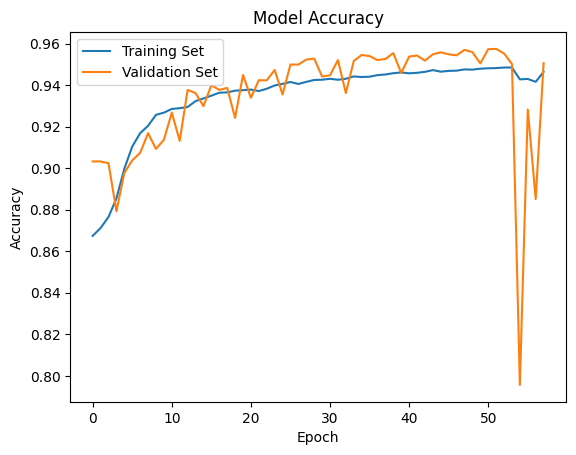

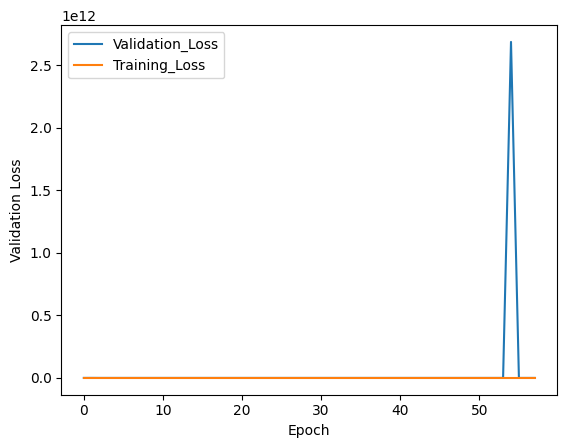

In [ ]:
print(results.history)
ax1 = plt.plot(results.history['accuracy'])
ax1 = plt.plot(results.history['val_accuracy'])
ax1 = plt.title('Model Accuracy')
ax1 = plt.ylabel('Accuracy')
ax1 = plt.xlabel('Epoch')
ax1 = plt.legend(['Training Set', 'Validation Set'])
plt.show()
ax2 = plt.plot(results.history['val_loss'])
ax2=plt.plot(results.history['loss'])
ax2 = plt.ylabel('Validation Loss')
ax2 = plt.xlabel('Epoch')
ax2 = plt.legend(['Validation_Loss', 'Training_Loss'])
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 35s 15s/step
Precision     : 0.9047
Recall        : 0.7800
F1 Score      : 0.8377
Dice Score    : 0.8377
Accuracy      : 0.9628
IoU Score     : 0.7208
Confusion Matrix:
[[11135607   129804]
 [  347547  1232098]]


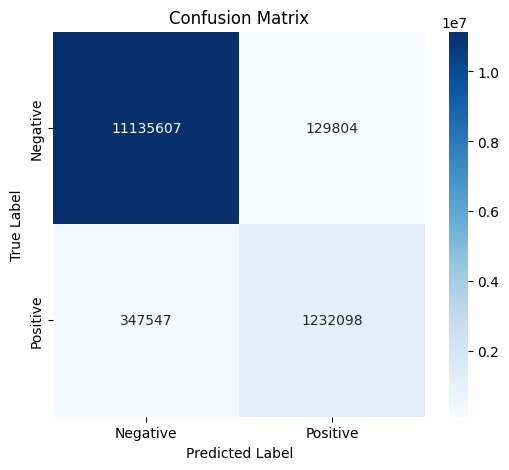

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# Assuming the rest of the code is already executed:
y_pred = model.predict(X_test)
y_pred_binary = (y_pred > 0.5).astype(np.bool_)
y_true_flat = y_test_ground_truth.flatten()
y_pred_flat = y_pred_binary.flatten()

# Metrics
precision = precision_score(y_true_flat, y_pred_flat)
recall = recall_score(y_true_flat, y_pred_flat)
f1 = f1_score(y_true_flat, y_pred_flat)
accuracy = accuracy_score(y_true_flat, y_pred_flat)
conf_matrix = confusion_matrix(y_true_flat, y_pred_flat)
tn, fp, fn, tp = confusion_matrix(y_true_flat, y_pred_flat).ravel()
iou = tp / (tp + fp + fn)
# Print metrics
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1 Score      : {f1:.4f}")
print(f"Dice Score    : {f1:.4f}")
print(f"Accuracy      : {accuracy:.4f}")
print(f"IoU Score     : {iou:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)

print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 49/49 [00:03<00:00, 13.95it/s]


In [ ]:
idx = random.randint(1,len(X_train))

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

#Probability thresholds --------------------------------------------------------------------
pred_train_t = (pred_train>0.3).astype(np.uint8)
pred_val_t = (pred_val>0.3).astype(np.uint8)
pred_test_t = (pred_test>0.3).astype(np.uint8)

#checking performance on entire test set

for i in range(0,test_img_count):

    imshow(X_test[i])
    plt.axis('off')
    plt.show()
    imshow(pred_test[i])
    #imshow(np.squeeze(pred_test[i]))
    plt.axis('off')
    plt.show()
    #imshow(np.squeeze(pred_test_t[i]))
    imshow(pred_test_t[i])
    plt.axis('off')
    plt.show()


In [ ]:
#checking performance on entire test set

for i in range(0,len(test_img_ids)):
    fig, ((ax0, ax1, ax2)) = plt.subplots(1,3, figsize=(20,7))

    ax0.imshow(X_test[i])
    ax0.axis('off')s
    ax0.set_title('Satellite Map %s'%(test_img_ids[i]))

    ax1.imshow(np.squeeze(y_test_ground_truth[i]+0))
    ax1.axis('off')
    ax1.set_title('Ground Truth Mask %s'%(test_img_ids[i]))

    # continuous mask
    ax2.imshow(np.squeeze(pred_test_t[i]))
    ax2.axis('off')
    ax2.set_title('Predicted Mask %s'%(test_img_ids[i]))


Tuning on validation images...
  thr=0.30 gap= 0 spur= 0 -> val APLS 0.5423
  thr=0.30 gap= 0 spur=10 -> val APLS 0.5700
  thr=0.30 gap=20 spur= 0 -> val APLS 0.5373
  thr=0.30 gap=20 spur=10 -> val APLS 0.5590
  thr=0.40 gap= 0 spur= 0 -> val APLS 0.5579
  thr=0.40 gap= 0 spur=10 -> val APLS 0.5585
  thr=0.40 gap=20 spur= 0 -> val APLS 0.5692
  thr=0.40 gap=20 spur=10 -> val APLS 0.5746
  thr=0.50 gap= 0 spur= 0 -> val APLS 0.5357
  thr=0.50 gap= 0 spur=10 -> val APLS 0.5348
  thr=0.50 gap=20 spur= 0 -> val APLS 0.5595
  thr=0.50 gap=20 spur=10 -> val APLS 0.5480
Best settings: {'thr': 0.4, 'max_gap': 20, 'spur': 10}  (val APLS 0.5746)

Image 001 - APLS: 0.1972
Image 002 - APLS: 0.6210
Image 003 - APLS: 0.3129
Image 004 - APLS: 0.7190
Image 005 - APLS: 0.6510
Image 006 - APLS: 0.7823
Image 007 - APLS: 0.6647
Image 008 - APLS: 0.5700
Image 009 - APLS: 0.7534
Image 010 - APLS: 0.7262
Image 011 - APLS: 0.8093
Image 012 - APLS: 0.7879
Image 013 - APLS: 0.6515
Image 014 - APLS: 0.8432
Imag

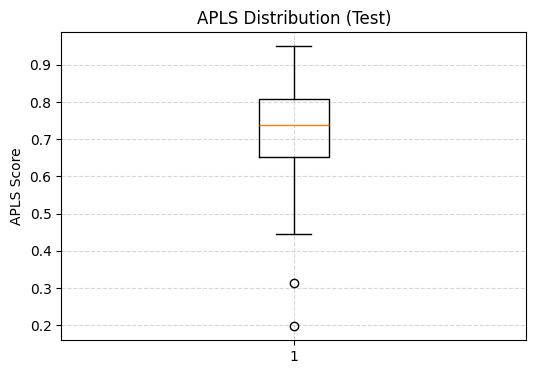

In [ ]:
# ============ APLS EVALUATION: improved, single cell ============
# Needs: model, X_test, y_test_ground_truth, X_train, y_train

import numpy as np, networkx as nx, random, itertools, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.ndimage import convolve
from skimage.morphology import skeletonize, remove_small_objects, binary_closing, disk
from skimage.measure import label
from skimage.draw import line

# ---------------- Settings ----------------
USE_TTA   = True            # 8x flip/rotate averaging (slower, better)
TUNE      = True            # tune postprocessing on VALIDATION data (not test)
N_VAL     = 20              # validation images used for tuning
GRID_THR  = (0.3, 0.4, 0.5)
GRID_GAP  = (0, 20)         # max gap (px) to bridge
GRID_SPUR = (0, 10)         # spur length (px) to prune
DEFAULT   = dict(thr=0.4, max_gap=20, spur=10)   # used if TUNE=False
MIN_SIZE, CLOSE_R = 150, 2
BUFFER, N_NODES, SEED = 4, 60, 42

# ---------------- Prediction (optional TTA) ----------------
def predict_probs(X, bs=4):
    if not USE_TTA:
        return model.predict(X, batch_size=bs, verbose=0)
    out = np.zeros(X.shape[:3] + (1,), np.float32)
    for k in range(4):
        for flip in (False, True):
            x = np.rot90(X, k, axes=(1, 2))
            if flip: x = x[:, :, ::-1]
            p = model.predict(np.ascontiguousarray(x), batch_size=bs, verbose=0)
            if flip: p = p[:, :, ::-1]
            out += np.rot90(p, -k, axes=(1, 2))
    return out / 8.0

# ---------------- Mask -> skeleton -> graph ----------------
def bridge_gaps(skel, max_gap):
    if max_gap <= 0: return skel
    skel = skel.copy()
    pts = np.argwhere(skel)
    if len(pts) < 2: return skel
    lab = label(skel, connectivity=2)
    nb = convolve(skel.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant") - 1
    ends = np.argwhere(skel & (nb == 1))
    tree = cKDTree(pts)
    kq = min(100, len(pts))
    for y, x in ends:
        d, j = tree.query([y, x], k=kq, distance_upper_bound=max_gap)
        for dd, jj in zip(np.atleast_1d(d), np.atleast_1d(j)):
            if np.isinf(dd): break
            py, px = pts[jj]
            if lab[py, px] != lab[y, x]:           # different component -> connect
                rr, cc = line(y, x, py, px); skel[rr, cc] = True
                break
    return skeletonize(skel)

def pred_to_skeleton(prob, thr, max_gap):
    m = prob.squeeze() > thr
    if CLOSE_R > 0: m = binary_closing(m, disk(CLOSE_R))
    if MIN_SIZE > 0: m = remove_small_objects(m, MIN_SIZE)
    return bridge_gaps(skeletonize(m), max_gap)

def skel_to_graph(skel):
    pts = set(map(tuple, np.argwhere(skel)[:, ::-1]))      # (x, y)
    G = nx.Graph(); G.add_nodes_from(pts)
    for (x, y) in pts:
        for dx, dy in ((1, 0), (0, 1), (1, 1), (1, -1)):   # each pair once
            q = (x + dx, y + dy)
            if q in pts: G.add_edge((x, y), q, weight=float(np.hypot(dx, dy)))
    return G

def prune_spurs(G, min_len):
    if min_len <= 0: return G
    G = G.copy()
    for n in [n for n in G.nodes if G.degree(n) == 1]:
        if n not in G: continue
        path, cur, prev = [n], n, None
        while True:
            nxt = [m for m in G.neighbors(cur) if m != prev]
            if len(nxt) != 1: break
            prev, cur = cur, nxt[0]; path.append(cur)
            if G.degree(cur) != 2: break
        if G.degree(cur) >= 3 and len(path) < min_len:
            G.remove_nodes_from(path[:-1])                  # keep the junction
    return G

def key_nodes(G): return [n for n in G.nodes if G.degree(n) != 2]

# ---------------- APLS (symmetric, snapped, normalised by GT length) ----------------
def apls_one_direction(G_a, G_b):
    nodes = key_nodes(G_a)
    if len(nodes) < 2: return None
    if G_b.number_of_nodes() == 0: return 0.0
    nodes = random.Random(SEED).sample(nodes, min(N_NODES, len(nodes)))
    b_nodes = list(G_b.nodes)
    dist, idx = cKDTree(np.array(b_nodes)).query(np.array(nodes))
    snap = [b_nodes[i] if d <= BUFFER else None for d, i in zip(dist, idx)]
    scores = []
    for i in range(len(nodes)):
        len_a = nx.single_source_dijkstra_path_length(G_a, nodes[i], weight="weight")
        len_b = (nx.single_source_dijkstra_path_length(G_b, snap[i], weight="weight")
                 if snap[i] is not None else {})
        for j in range(i + 1, len(nodes)):
            if nodes[j] not in len_a: continue              # no route in reference
            L_a = len_a[nodes[j]]
            if L_a == 0: continue
            if snap[i] is None or snap[j] is None or snap[j] not in len_b:
                scores.append(0.0)
            else:
                scores.append(1.0 - min(1.0, abs(L_a - len_b[snap[j]]) / L_a))
    return float(np.mean(scores)) if scores else None

def apls(G_gt, G_pr):
    p = apls_one_direction(G_gt, G_pr)                      # missed roads
    if p is None: return np.nan
    q = apls_one_direction(G_pr, G_gt); q = 0.0 if q is None else q   # false roads
    return 2 * p * q / (p + q + 1e-8)

def evaluate(probs, gts, thr, max_gap, spur, verbose=False):
    scores = []
    for i in range(len(probs)):
        G_gt = skel_to_graph(skeletonize(gts[i].squeeze() > 0.5))
        G_pr = prune_spurs(skel_to_graph(pred_to_skeleton(probs[i], thr, max_gap)), spur)
        s = apls(G_gt, G_pr); scores.append(s)
        if verbose:
            print(f"Image {i+1:03d} - APLS: {s:.4f}" if not np.isnan(s)
                  else f"Image {i+1:03d} - skipped (no GT roads)")
    return np.array(scores)

# ---------------- Tune on validation (never on test) ----------------
best = DEFAULT
if TUNE:
    if "va_idx" in globals():
        val_ids = va_idx
    else:                                                    # matches Keras validation_split=0.2
        val_ids = np.arange(int(len(X_train) * 0.8), len(X_train))
    val_ids = val_ids[:N_VAL]
    Pv, Gv = predict_probs(X_train[val_ids]), y_train[val_ids]
    best_score = -1
    print("Tuning on validation images...")
    for thr, gap, sp in itertools.product(GRID_THR, GRID_GAP, GRID_SPUR):
        sc = np.nanmean(evaluate(Pv, Gv, thr, gap, sp))
        print(f"  thr={thr:.2f} gap={gap:2d} spur={sp:2d} -> val APLS {sc:.4f}")
        if sc > best_score: best_score, best = sc, dict(thr=thr, max_gap=gap, spur=sp)
    print(f"Best settings: {best}  (val APLS {best_score:.4f})\n")

# ---------------- Final test evaluation ----------------
Y_pred_prob = predict_probs(X_test)
scores = evaluate(Y_pred_prob, y_test_ground_truth, verbose=True, **best)
valid = scores[~np.isnan(scores)]

print("\n=========== APLS SUMMARY (TEST) ===========")
print(f"Settings         : {best}")
print(f"Images evaluated : {len(valid)} / {len(scores)}")
print(f"Mean APLS        : {valid.mean():.4f}")
print(f"Median APLS      : {np.median(valid):.4f}")
print(f"Std              : {valid.std():.4f}")
print("===========================================")

plt.figure(figsize=(6, 4)); plt.boxplot(valid)
plt.ylabel("APLS Score"); plt.title("APLS Distribution (Test)")
plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [ ]:

import tensorflow as tf
import numpy as np
import time
import os
import statistics

# ==========================================
# 1. MODEL PARAMETER COUNT
# ==========================================

total_params = model.count_params()

trainable_params = np.sum([
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
])

non_trainable_params = total_params - trainable_params

print("\n========== MODEL PARAMETERS ==========")
print(f"Total Parameters       : {total_params:,}")
print(f"Trainable Parameters   : {trainable_params:,}")
print(f"Non-trainable Params   : {non_trainable_params:,}")
print(f"Total Parameters (M)   : {total_params / 1e6:.4f}")


# ==========================================
# 2. FLOPs CALCULATION
# ==========================================

def calculate_flops(model, input_shape=(1, 512, 512, 3)):

    try:
        from tensorflow.python.framework.convert_to_constants import (
            convert_variables_to_constants_v2
        )

        # Create a concrete inference function
        input_spec = tf.TensorSpec(
            shape=input_shape,
            dtype=tf.float32
        )

        @tf.function
        def forward_pass(x):
            return model(x, training=False)

        concrete_func = forward_pass.get_concrete_function(input_spec)

        # Freeze model variables
        frozen_func = convert_variables_to_constants_v2(
            concrete_func
        )

        graph_def = frozen_func.graph.as_graph_def()

        # Import frozen graph
        with tf.Graph().as_default() as graph:

            tf.graph_util.import_graph_def(
                graph_def,
                name=""
            )

            # Calculate floating-point operations
            profiler_options = (
                tf.compat.v1.profiler.ProfileOptionBuilder
                .float_operation()
            )

            profiler_options['output'] = 'none'

            flops_result = tf.compat.v1.profiler.profile(
                graph=graph,
                options=profiler_options
            )

        if flops_result is not None:
            return flops_result.total_float_ops

        return None

    except Exception as e:
        print("FLOPs calculation error:", str(e))
        return None


flops = calculate_flops(model)

print("\n========== COMPUTATIONAL COMPLEXITY ==========")

if flops is not None:
    print(f"Total FLOPs             : {flops:,}")
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs could not be calculated.")


# ==========================================
# 3. INFERENCE SPEED (BATCH SIZE = 1)
# ==========================================

IMG_SIZE = 512
INPUT_CHANNELS = 3

# Single input image
dummy_input = np.random.rand(
    1, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up runs
for _ in range(20):
    output = model(dummy_input, training=False)
    _ = output.numpy()  # Synchronize execution

# Actual inference measurement
num_runs = 100
inference_times = []

for _ in range(num_runs):

    start_time = time.perf_counter()

    output = model(dummy_input, training=False)

    # Synchronize GPU/CPU execution
    _ = output.numpy()

    end_time = time.perf_counter()

    inference_times.append(
        (end_time - start_time) * 1000
    )

mean_latency = np.mean(inference_times)
median_latency = np.median(inference_times)
std_latency = np.std(inference_times)

throughput = 1000.0 / mean_latency

print("\n========== INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : 1")
print(f"Number of Runs          : {num_runs}")
print(f"Mean Inference Time     : {mean_latency:.4f} ms")
print(f"Median Inference Time   : {median_latency:.4f} ms")
print(f"Standard Deviation      : {std_latency:.4f} ms")
print(f"Inference Throughput    : {throughput:.2f} images/sec")


# ==========================================
# 4. BATCH INFERENCE PERFORMANCE
# ==========================================

batch_size = 16

batch_input = np.random.rand(
    batch_size, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up
for _ in range(10):
    output = model(batch_input, training=False)
    _ = output.numpy()

batch_runs = 30
batch_times = []

for _ in range(batch_runs):

    start_time = time.perf_counter()

    output = model(batch_input, training=False)

    _ = output.numpy()

    end_time = time.perf_counter()

    batch_times.append(end_time - start_time)

mean_batch_time = np.mean(batch_times)

batch_latency = (mean_batch_time / batch_size) * 1000

batch_throughput = batch_size / mean_batch_time

print("\n========== BATCH INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : {batch_size}")
print(f"Mean Batch Time         : {mean_batch_time * 1000:.4f} ms")
print(f"Latency Per Image       : {batch_latency:.4f} ms")
print(f"Batch Throughput        : {batch_throughput:.2f} images/sec")


# ==========================================
# 5. MODEL STORAGE SIZE
# ==========================================

model_path = "SE_Residual_Attention_UNet.keras"

model.save(model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("\n========== MODEL STORAGE ==========")
print(f"Model Size              : {model_size_mb:.2f} MB")


# ==========================================
# 6. FINAL COMPUTATIONAL SUMMARY
# ==========================================

print("\n========== FINAL MODEL SUMMARY ==========")

print(f"Parameters (M)          : {total_params / 1e6:.4f}")

if flops is not None:
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs (G)               : Not available")

print(f"Model Size (MB)         : {model_size_mb:.2f}")
print(f"Inference Time (ms)     : {mean_latency:.4f}")
print(f"Throughput (img/sec)    : {throughput:.2f}")
print(f"Batch-16 Throughput     : {batch_throughput:.2f}")



========== MODEL PARAMETERS ==========
Total Parameters       : 9,196,209
Trainable Parameters   : 9,184,593
Non-trainable Params   : 11,616
Total Parameters (M)   : 9.1962


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



========== COMPUTATIONAL COMPLEXITY ==========
Total FLOPs             : 131,318,712,488
FLOPs (G)               : 131.3187

========== INFERENCE PERFORMANCE ==========
Batch Size              : 1
Number of Runs          : 100
Mean Inference Time     : 192.4799 ms
Median Inference Time   : 192.0937 ms
Standard Deviation      : 1.5814 ms
Inference Throughput    : 5.20 images/sec

========== BATCH INFERENCE PERFORMANCE ==========
Batch Size              : 16
Mean Batch Time         : 253.9736 ms
Latency Per Image       : 15.8734 ms
Batch Throughput        : 63.00 images/sec

========== MODEL STORAGE ==========
Model Size              : 105.81 MB

========== FINAL MODEL SUMMARY ==========
Parameters (M)          : 9.1962
FLOPs (G)               : 131.3187
Model Size (MB)         : 105.81
Inference Time (ms)     : 192.4799
Throughput (img/sec)    : 5.20
Batch-16 Throughput     : 63.00
